# 01 — Análise exploratória dos dados J1939

Dados decodificados dos logs CAN do Kenworth T270 2014 (Colorado State University), reamostrados a 1 Hz.

- **Treino:** `CSU090BJ` (viagem contínua de ~4,2 h)
- **Teste:** `cross_country` (~16 h, 8 segmentos)

Objetivos: entender os sinais, os estados de operação, as relações entre variáveis e **quanto o teste difere do treino**.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

P = Path("../data/processed"); FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
bj = pd.read_parquet(P / "CSU090BJ.parquet")
cc = pd.read_parquet(P / "2014_KW_T270_cross_country_can_log.parquet")
SIG = [c for c in bj.columns if c not in ("ts", "segment", "engine_on")]
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()
print(len(bj), len(cc)); SIG

15124 57846


['engine_torque_pct',
 'rpm',
 'pedal_pct',
 'load_pct',
 'gear',
 'coolant_c',
 'oil_kpa',
 'speed_kmh',
 'fuel_rate_lph',
 'boost_kpa',
 'intake_c',
 'battery_v',
 'odometer_km',
 'fuel_level_pct']

## 1. Resumo estatístico (somente motor ligado)

In [2]:
on = lambda d: d[d.engine_on]
pd.concat({"treino (BJ)": on(bj)[SIG].describe().T[["mean","std","min","max"]],
           "teste (cross-country)": on(cc)[SIG].describe().T[["mean","std","min","max"]]}, axis=1).round(2)

treino (BJ)                                \
                         mean     std        min        max   
engine_torque_pct       46.57   16.60       0.00      89.00   
rpm                   2022.90  171.57     120.33    2160.43   
pedal_pct               13.25   28.99       0.00     100.00   
load_pct                55.55   18.44       0.00     100.00   
gear                     4.92    0.52       0.00       5.00   
coolant_c               90.25    1.13      78.00      93.00   
oil_kpa                351.17   27.11       0.00     366.00   
speed_kmh              101.68   13.72       0.00     106.02   
fuel_rate_lph           19.74    7.25       0.00      41.16   
boost_kpa               71.64   28.32       0.00     157.00   
intake_c                50.39    2.06      44.00      63.00   
battery_v               14.01    0.04      11.35      14.15   
odometer_km         426264.48  124.87  426053.25  426477.62   
fuel_level_pct          92.21    7.73      76.40     100.00   

                  teste (cross-country)                                
                                   mean     std        min        max  
engine_torque_pct                 42.49   16.72       0.00      93.00  
rpm                             1941.10  326.24      13.72    2237.83  
pedal_pct                         13.92   30.05       0.00     100.00  
load_pct                          51.19   18.31       0.00     100.00  
gear                               4.67    1.12      -1.00       5.00  
coolant_c                         89.39    6.02      27.00      95.00  
oil_kpa                          340.09   47.73       0.00     402.00  
speed_kmh                         95.10   26.42       0.00     108.55  
fuel_rate_lph                     17.75    7.70       0.00      46.91  
boost_kpa                         67.46   30.47       0.00     187.00  
intake_c                          52.71    5.18      30.00      68.00  
battery_v                         13.99    0.10      11.30      14.20  
odometer_km                   425723.49  436.41  424997.50  426477.62  
fuel_level_pct                    64.33   26.76       2.80     100.00

## 2. Séries temporais — primeira hora do treino

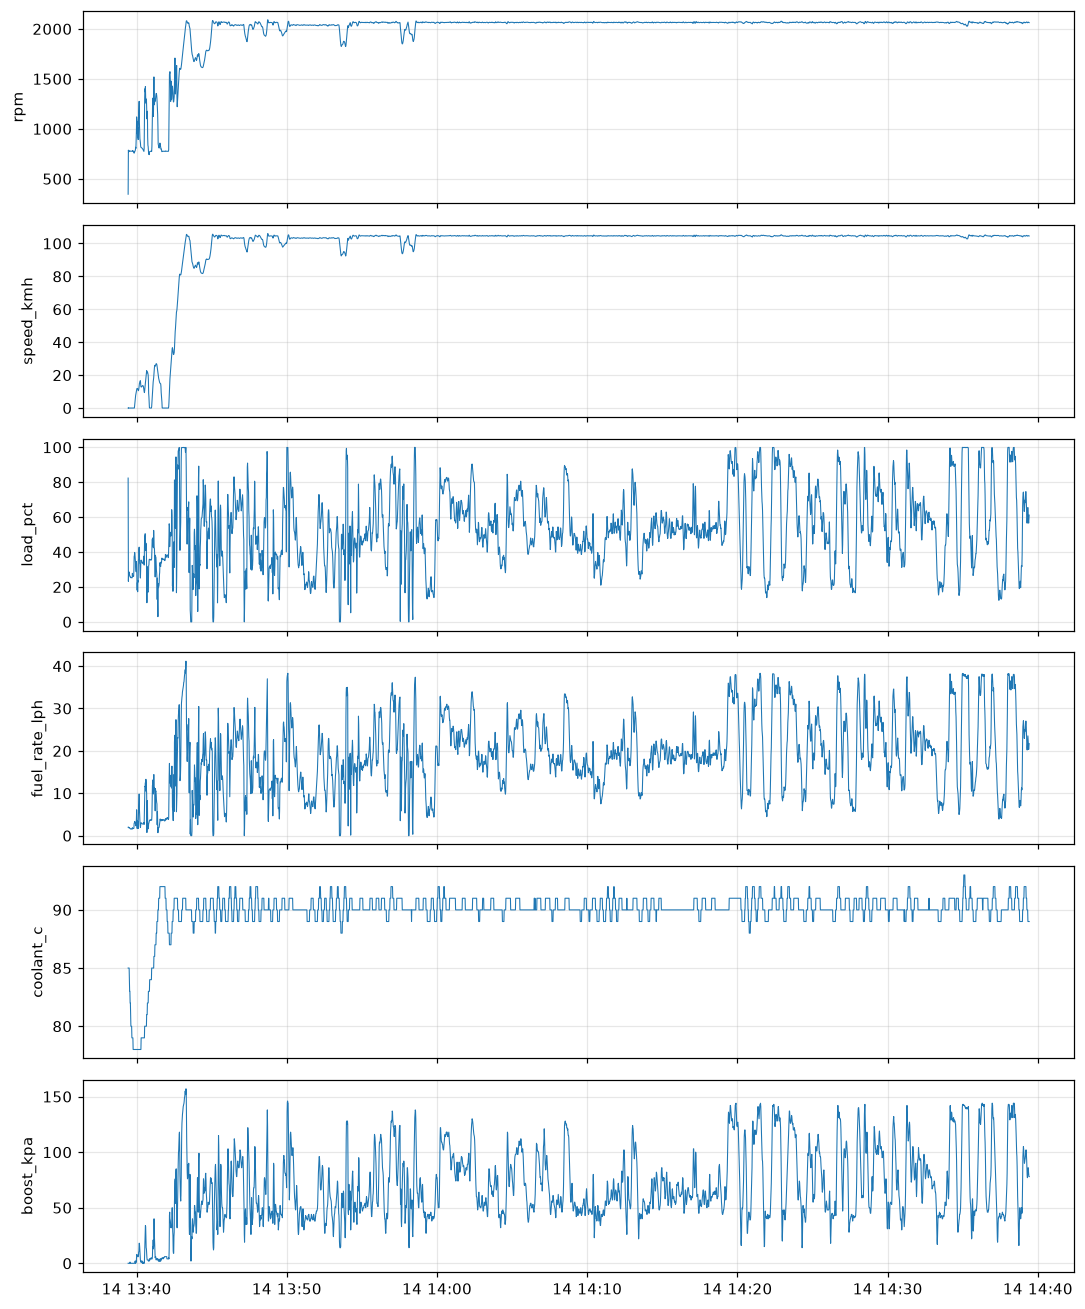

In [3]:
d = on(bj).iloc[:3600].set_index("ts")
cols = ["rpm", "speed_kmh", "load_pct", "fuel_rate_lph", "coolant_c", "boost_kpa"]
fig, ax = plt.subplots(len(cols), 1, figsize=(10, 12), sharex=True)
for a, c in zip(ax, cols): a.plot(d.index, d[c], lw=.7); a.set_ylabel(c)
save("series_bj_1h")

## 3. Distribuições: treino × teste

Se as distribuições forem muito diferentes, o limiar de anomalia aprendido no treino pode gerar falsos positivos no teste.

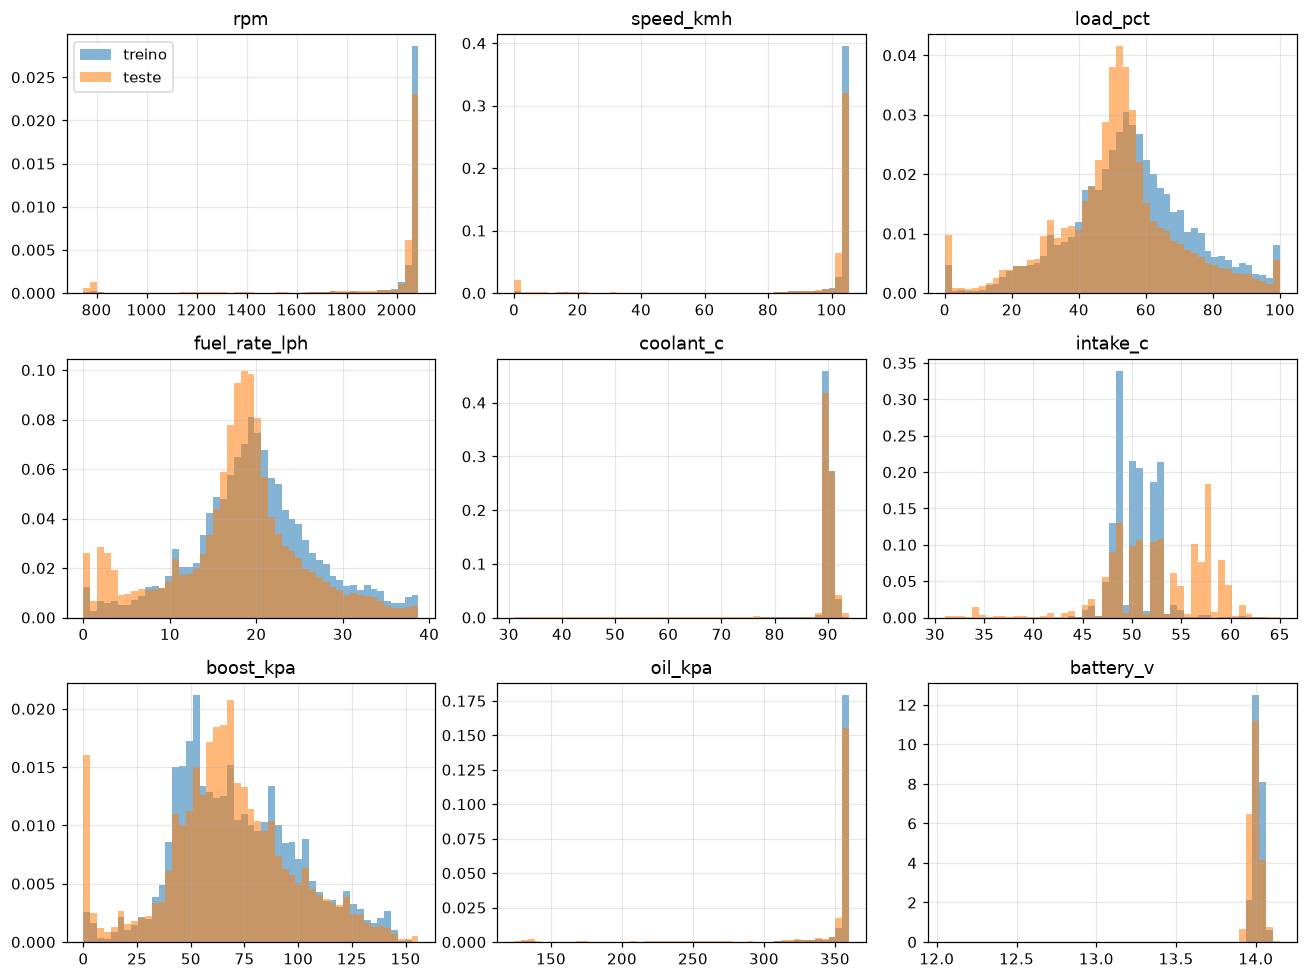

In [4]:
cols = ["rpm","speed_kmh","load_pct","fuel_rate_lph","coolant_c","intake_c","boost_kpa","oil_kpa","battery_v"]
fig, ax = plt.subplots(3, 3, figsize=(12, 9))
for a, c in zip(ax.ravel(), cols):
    lo, hi = on(bj)[c].quantile(.001), on(bj)[c].quantile(.999)
    bins = np.linspace(min(lo, on(cc)[c].quantile(.001)), max(hi, on(cc)[c].quantile(.999)), 50)
    a.hist(on(bj)[c].dropna(), bins, density=True, alpha=.55, label="treino")
    a.hist(on(cc)[c].dropna(), bins, density=True, alpha=.55, label="teste"); a.set_title(c)
ax[0,0].legend(); save("distribuicoes_treino_teste")

## 4. Correlações (motor ligado, treino)

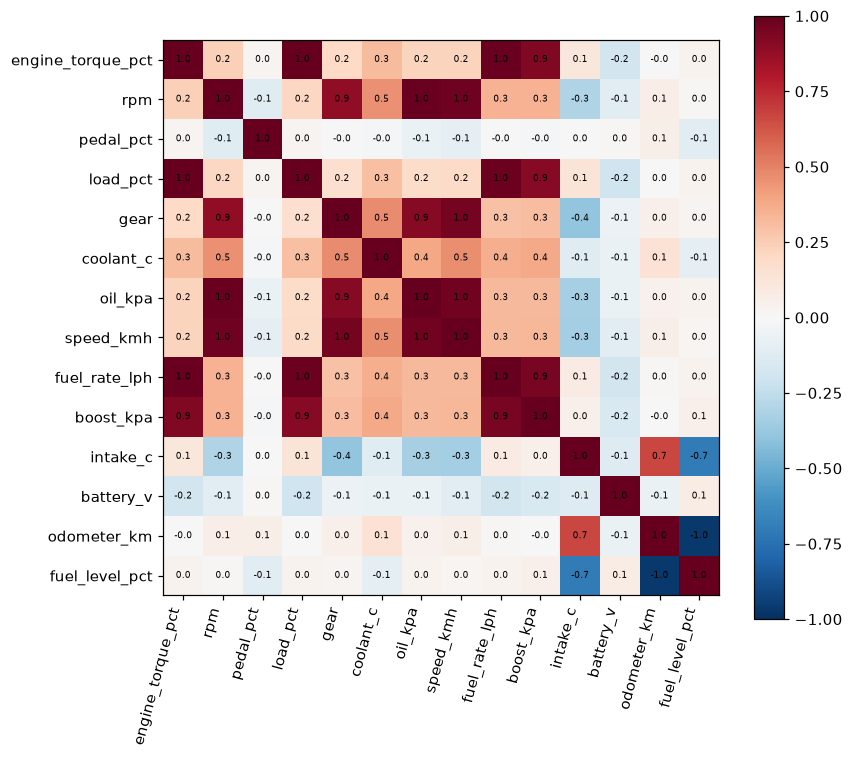

In [5]:
corr = on(bj)[SIG].corr()
fig, a = plt.subplots(figsize=(8, 7)); im = a.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
a.set_xticks(range(len(SIG)), SIG, rotation=75, ha="right"); a.set_yticks(range(len(SIG)), SIG); a.grid(False)
for i in range(len(SIG)):
    for j in range(len(SIG)): a.text(j, i, f"{corr.iloc[i,j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im); save("correlacao_bj")

## 5. Estados de operação

- **parado/marcha lenta:** motor ligado e velocidade < 1 km/h
- **cruzeiro:** velocidade ≥ 80 km/h
- **urbano/transição:** demais

In [6]:
def estado(d):
    d = on(d)
    return np.select([d.speed_kmh < 1, d.speed_kmh >= 80], ["parado", "cruzeiro"], "transição")
rows = {}
for nome, d in {"treino": bj, "teste": cc}.items():
    e = pd.Series(estado(d), index=on(d).index); g = on(d).groupby(e)
    rows[nome] = pd.DataFrame({"% tempo": g.size() / len(e) * 100, "rpm médio": g.rpm.mean(),
                               "consumo L/h": g.fuel_rate_lph.mean(), "carga %": g.load_pct.mean(),
                               "arrefec. °C": g.coolant_c.mean()}).round(1)
pd.concat(rows, axis=1)

treino                                             teste            \
          % tempo rpm médio consumo L/h carga % arrefec. °C % tempo rpm médio   
cruzeiro     97.6    2046.9        20.1    56.1        90.3    90.0    2041.7   
parado        0.7     766.5         2.8    32.9        87.0     4.2     770.4   
transição     1.8    1159.0         7.2    34.2        87.2     5.8    1232.4   

                                           
          consumo L/h carga % arrefec. °C  
cruzeiro         19.1    53.2        90.4  
parado            2.8    32.6        70.6  
transição         8.0    34.1        86.9

## 6. Relações físicas úteis para o regressor de valor esperado

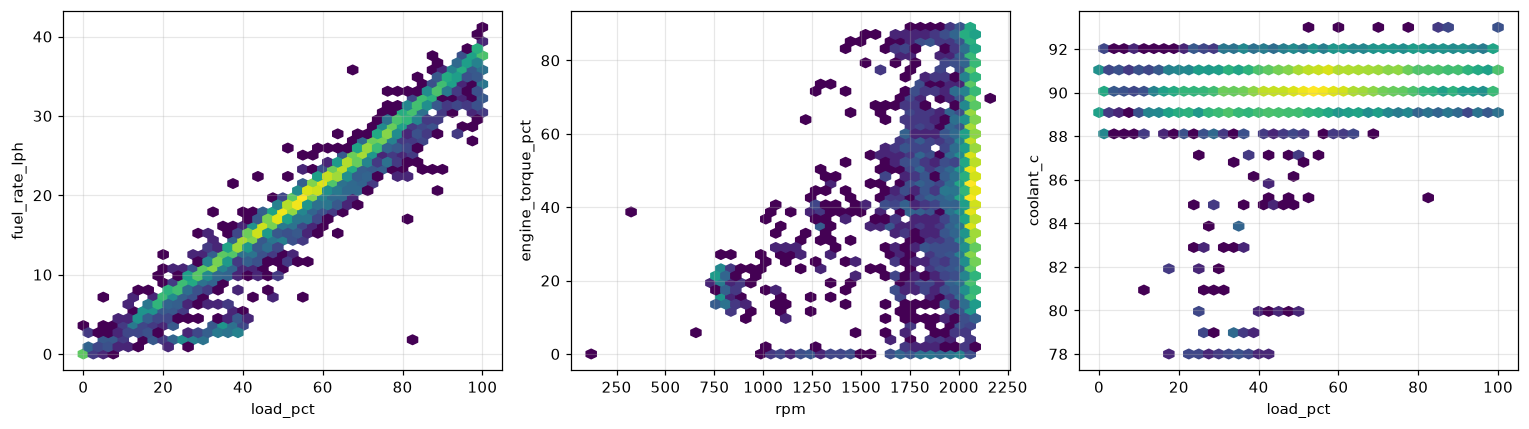

In [7]:
d = on(bj)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (x, y) in zip(ax, [("load_pct","fuel_rate_lph"), ("rpm","engine_torque_pct"), ("load_pct","coolant_c")]):
    h = a.hexbin(d[x], d[y], gridsize=40, mincnt=1, bins="log", cmap="viridis"); a.set_xlabel(x); a.set_ylabel(y)
save("relacoes_bj")

## 7. Segmentos do cross-country

In [8]:
g = cc.groupby("segment")
seg = pd.DataFrame({"início": g.ts.min(), "duração (h)": g.size() / 3600,
                    "distância (km)": g.odometer_km.max() - g.odometer_km.min(),
                    "combustível início %": g.fuel_level_pct.first(), "combustível fim %": g.fuel_level_pct.last(),
                    "vel. média km/h": g.speed_kmh.mean()}).round(1)
seg

/tmp/ipykernel_29049/2454584111.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "vel. média km/h": g.speed_kmh.mean()}).round(1)


,início,duração (h),distância (km),combustível início %,combustível fim %,vel. média km/h
segment,,,,,,
0,2020-07-13 17:11:11+00:00,5.7,525.9,86.8,48.4,91.6
1,2020-07-13 23:12:29+00:00,0.2,0.0,48.0,48.0,0.0
2,2020-07-13 23:36:10+00:00,5.1,516.1,0.0,4.4,101.1
3,2020-07-14 04:56:29+00:00,0.0,0.0,100.0,100.0,0.0
4,2020-07-14 05:01:13+00:00,0.3,8.2,100.0,100.0,25.6
5,2020-07-14 12:41:12+00:00,0.2,2.5,0.0,100.0,10.6
6,2020-07-14 13:07:16+00:00,0.2,3.0,100.0,100.0,15.7
7,2020-07-14 13:39:09+00:00,4.2,424.4,100.0,78.0,100.8


## Conclusões

1. **O treino (BJ) é quase só cruzeiro:** 97,6% do tempo a ~100 km/h e ~2000 rpm, com arrefecimento em 90 ± 1 °C. Um detector de anomalias treinado só nele aprende um "normal" muito estreito.
2. **O teste tem estados que o treino quase não vê:** 4,2% parado/marcha lenta (0,7% no treino), partidas a frio (arrefecimento de 27 °C) e `gear` = −1 (ré). Esses casos legítimos seriam sinalizados como anomalia (falsos positivos).
3. **Relações físicas claras** (carga → consumo, RPM → torque) — bom para o regressor de valor esperado, que é robusto a mudanças de estado se tiver RPM, carga e velocidade como entradas.
4. **`fuel_level_pct`:** os 0% aparecem só nos primeiros segundos de cada segmento (inicialização do nó 0x31) e são tratados como ausentes. No restante o nível é consistente: 87 → 48% (seg. 0), 47 → 3% (seg. 2) e 100 → 78% (seg. 7), com reabastecimentos entre segmentos. No BJ o nível quase não varia. A tabela da seção 7 usa `first()`, que pega esses zeros de partida; interpretar com cuidado.
5. **Segmentos curtos** (1, 3, 4, 5, 6 do cross-country: ≤ 0,3 h) são manobras/paradas; os longos são os segmentos 0, 2 e 7 (4–6 h, 420–525 km).
